<a href="https://colab.research.google.com/github/2anoFIAP/AED-KPOP-CP-DATASCIENCE/blob/main/CP_AED.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AED — shows de K-pop

## 1. Contextualização

### Pergunta central
Quais fatores estão associados à lucratividade da operação dos shows de K-pop?

### Contexto e limites
A base contém shows programados entre 2023 e 2025. Os nomes dos grupos são reais, mas os eventos e indicadores são simulados para fins educacionais.

Os resultados financeiros representam a operação de realização dos shows, não o lucro total dos grupos, artistas ou agências.

### Unidade de análise
Cada linha representa um show programado, inclusive quando cancelado. Também serão utilizadas agregações por turnê para avaliar o resultado da programação.

### Objetivo
Investigar relações entre características dos shows, contexto de mercado e desempenho financeiro, desenvolvendo pelo menos três insights e três ações vinculadas às evidências.

### Cuidados metodológicos
- Manter cancelamentos na avaliação financeira da operação.
- Não substituir automaticamente dados ausentes por zero.
- Distinguir lucro absoluto, margem e frequência de prejuízo.
- Considerar a dependência entre shows do mesmo grupo ou turnê.
- Interpretar associações sem presumir causalidade.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    "kpop_shows.csv",
    encoding="utf-8-sig",
    parse_dates=["data_show"]
)
df.head(5)

,id_show,dados_simulados,grupo,integrante_referencia,ano_estreia_grupo,data_show,ano,id_turne,ordem_show_turne,shows_planejados_turne,...,custo_marketing_usd,custo_produtos_usd,repasse_artistas_usd,comissao_promotor_usd,impostos_usd,rateio_abertura_turne_usd,receita_total_usd,custo_total_usd,lucro_operacional_usd,satisfacao_publico_0a10
0,K00001,True,TWICE,Jihyo,2015,2023-02-02,2023,T01-2023-1,1,8,...,54473.49,31141.86,54022.94,43156.84,32674.04,12555.79,523755.27,292376.31,231378.96,8.0
1,K00002,True,TWICE,Jihyo,2015,2023-02-05,2023,T01-2023-1,2,8,...,65081.42,91751.78,268334.08,198778.53,226494.08,12555.79,2357054.06,972198.04,1384856.02,8.5
2,K00003,True,TWICE,Jihyo,2015,2023-02-08,2023,T01-2023-1,3,8,...,86207.86,48788.28,179820.49,199192.56,68062.84,12555.79,1659454.20,672432.22,987021.98,7.2
3,K00004,True,TWICE,Jihyo,2015,2023-02-14,2023,T01-2023-1,4,8,...,50474.08,86804.44,310560.84,381878.22,137238.80,12555.79,2808116.01,1177750.74,1630365.27,8.4
4,K00005,True,TWICE,Jihyo,2015,2023-02-17,2023,T01-2023-1,5,8,...,40516.19,76202.43,226245.20,275082.71,162844.01,12555.79,1912873.37,934102.64,978770.73,7.5


## 2. Compreensão e inspeção dos dados

Antes de qualquer limpeza, vamos verificar a estrutura da base, os tipos das variáveis, a cobertura dos registros, possíveis duplicidades e os valores ausentes.

In [4]:
df_original = df.copy(deep=True)

print(f"Dimensões: {df.shape[0]:,} linhas e {df.shape[1]} colunas")
print(f"Grupos: {df['grupo'].nunique()}")
print(f"Turnês: {df['id_turne'].nunique()}")
print(f"Período: {df['data_show'].min():%d/%m/%Y}"
    f" a {df['data_show'].max():%d/%m/%Y}")

print("\nTipos e preenchimento das colunas:")
df.info()

print("\nStatus dos shows:")
display(df["status_show"].value_counts(dropna=False).rename_axis("status_show").to_frame("quantidade"))

print("\nVerificação de duplicidades:")
print(f"Linhas inteiramente duplicadas: {df.duplicated().sum()}")
print(f"IDs de show ausentes: {df['id_show'].isna().sum()}")
print(f"IDs de show duplicados: {df['id_show'].duplicated().sum()}")

ausentes = pd.DataFrame({
    "quantidade_ausente": df.isna().sum(),
    "percentual_ausente": df.isna().mean().mul(100)
})

ausentes = (
    ausentes.loc[ausentes["quantidade_ausente"] > 0]
    .sort_values("quantidade_ausente", ascending=False)
)

print("\nColunas com dados ausentes:")
display(ausentes.round(2))

Dimensões: 1,902 linhas e 48 colunas
Grupos: 20
Turnês: 180
Período: 20/01/2023 a 07/09/2025

Tipos e preenchimento das colunas:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1902 entries, 0 to 1901
Data columns (total 48 columns):
 #   Column                           Non-Null Count  Dtype         
---  ------                           --------------  -----         
 0   id_show                          1902 non-null   object        
 1   dados_simulados                  1902 non-null   bool          
 2   grupo                            1902 non-null   object        
 3   integrante_referencia            1902 non-null   object        
 4   ano_estreia_grupo                1902 non-null   int64         
 5   data_show                        1902 non-null   datetime64[ns]
 6   ano                              1902 non-null   int64         
 7   id_turne                         1902 non-null   object        
 8   ordem_show_turne                 1902 non-null   int64         
 9   

,quantidade
status_show,
realizado,1878
cancelado,24



Verificação de duplicidades:
Linhas inteiramente duplicadas: 0
IDs de show ausentes: 0
IDs de show duplicados: 0

Colunas com dados ausentes:


,quantidade_ausente,percentual_ausente
intervalo_show_anterior_dias,180,9.46
satisfacao_publico_0a10,88,4.63
seguidores_locais_milhoes,67,3.52
streams_locais_30_dias_milhoes,58,3.05


### 2.1. Investigação dos dados ausentes

As ausências serão examinadas conforme o significado de cada variável.

- O intervalo desde o show anterior não se aplica à primeira data da turnê.
- A satisfação não se aplica aos shows cancelados; sua ausência em shows realizados representa falta de avaliação.
- Seguidores e streams possuem medições incompletas, que não devem ser interpretadas como zero.

Antes de definir tratamentos, verificaremos se os padrões observados são compatíveis com essas interpretações.

In [5]:
# 1. O intervalo ausente corresponde à primeira data da turnê?
primeiro_show = df["ordem_show_turne"].eq(1)
intervalo_ausente = df["intervalo_show_anterior_dias"].isna()

print("Intervalo desde o show anterior:")
display(
    pd.crosstab(
        primeiro_show,
        intervalo_ausente,
        rownames=["primeiro_show_da_turne"],
        colnames=["intervalo_ausente"],
        margins=True
    )
)

# 2. Como a ausência de satisfação se distribui por status?
resumo_satisfacao = (
    df.groupby("status_show")
    .agg(
        total_shows=("id_show", "size"),
        satisfacao_registrada=("satisfacao_publico_0a10", "count")
    )
)

resumo_satisfacao["satisfacao_ausente"] = (
    resumo_satisfacao["total_shows"]
    - resumo_satisfacao["satisfacao_registrada"]
)

resumo_satisfacao["percentual_ausente"] = (
    resumo_satisfacao["satisfacao_ausente"]
    / resumo_satisfacao["total_shows"]
    * 100
)

print("\nPreenchimento da satisfação por status:")
display(resumo_satisfacao.round(2))

# 3. Quantos shows têm ausência em pelo menos uma medida de popularidade?
colunas_popularidade = [
    "seguidores_locais_milhoes",
    "streams_locais_30_dias_milhoes"
]

popularidade_incompleta = df[colunas_popularidade].isna().any(axis=1)

print(
    "\nShows com seguidores ou streams ausentes:",
    popularidade_incompleta.sum()
)
print(
    "Shows com ambas as medidas ausentes:",
    df[colunas_popularidade].isna().all(axis=1).sum()
)

print("\nAusência de popularidade por região:")
display(
    df.assign(popularidade_incompleta=popularidade_incompleta)
    .groupby("regiao")
    .agg(
        total_shows=("id_show", "size"),
        popularidade_incompleta=("popularidade_incompleta", "sum"),
        percentual_incompleto=("popularidade_incompleta", "mean")
    )
    .assign(
        percentual_incompleto=lambda tabela:
            tabela["percentual_incompleto"] * 100
    )
    .round(2)
)

Intervalo desde o show anterior:


intervalo_ausente,False,True,All
primeiro_show_da_turne,,,
False,1722,0,1722
True,0,180,180
All,1722,180,1902



Preenchimento da satisfação por status:


,total_shows,satisfacao_registrada,satisfacao_ausente,percentual_ausente
status_show,,,,
cancelado,24,0,24,100.00
realizado,1878,1814,64,3.41



Shows com seguidores ou streams ausentes: 118
Shows com ambas as medidas ausentes: 7

Ausência de popularidade por região:


,total_shows,popularidade_incompleta,percentual_incompleto
regiao,,,
America Latina,429,26,6.06
America do Norte,518,28,5.41
Asia,443,28,6.32
Europa,512,36,7.03


### 2.2. Decisões sobre dados ausentes

A base principal será preservada, sem exclusão global de linhas ou
preenchimento automático de ausências.

- **Intervalo entre shows:** manter ausente nas primeiras datas das turnês,
  pois não existe evento anterior. Análises de intervalo considerarão
  somente shows com evento anterior.
- **Satisfação:** analisar shows realizados com nota registrada.
  Há 64 realizados sem avaliação (3,41%), o que limita a cobertura
  e pode introduzir viés caso esses shows sejam diferentes dos demais.
- **Popularidade:** manter seguidores e streams ausentes na base.
  Cada análise utilizará os registros com as medidas necessárias,
  informando o número de observações utilizado.

As proporções regionais de ausência, isoladamente, não permitem
determinar o mecanismo de falta dos dados.

In [6]:
# Padronizar a grafia das cidades, preservada em df_original

cidades_antes = df["cidade"].nunique()

df["cidade"] = (df["cidade"].str.strip().str.replace(r"\s+", " ", regex=True).str.casefold())

print(f"Cidades distintas antes: {cidades_antes}")
print(f"Cidades distintas depois: {df['cidade'].nunique()}")

# Verificações: sinalizar problemas sem excluir registros
verificacoes = {
    "Ano diferente do ano da data":
        df["ano"].ne(df["data_show"].dt.year),

    "Capacidade menor ou igual a zero":
        df["capacidade"].le(0),

    "Público pagante negativo":
        df["publico_pagante"].lt(0),

    "Cortesias negativas":
        df["cortesias"].lt(0),

    "Público total acima da capacidade":
        (df["publico_pagante"] + df["cortesias"]).gt(df["capacidade"]),

    "Câmbio menor ou igual a zero":
        df["cambio_moeda_local_por_usd"].le(0),

    "Preço efetivo negativo":
        df["preco_medio_efetivo_moeda_local"].lt(0),

    "Desconto fora de 0 a 100":
        ~df["desconto_medio_pct"].between(0, 100),

    "Satisfação registrada fora de 0 a 10":
        df["satisfacao_publico_0a10"].notna()
        & ~df["satisfacao_publico_0a10"].between(0, 10),

    "Intervalo registrado negativo":
        df["intervalo_show_anterior_dias"].lt(0),

    "Status não previsto no dicionário":
        ~df["status_show"].isin(["realizado", "cancelado"]),

    "Cancelado com público ou cortesias diferentes de zero":
        df["status_show"].eq("cancelado")
        & (
            df["publico_pagante"].ne(0)
            | df["cortesias"].ne(0)
        )
}

resumo_verificacoes = pd.DataFrame({
    "verificacao": list(verificacoes),
    "registros_sinalizados": [
        int(mascara.sum()) for mascara in verificacoes.values()
    ]
})

display(resumo_verificacoes)

# Exibir os registros sinalizados para investigação, se houver
for nome, mascara in verificacoes.items():
    if mascara.any():
        print(f"\n{nome}:")
        display(df.loc[mascara].head(10))

Cidades distintas antes: 31
Cidades distintas depois: 18


,verificacao,registros_sinalizados
0,Ano diferente do ano da data,0
1,Capacidade menor ou igual a zero,0
2,Público pagante negativo,0
3,Cortesias negativas,0
4,Público total acima da capacidade,0
5,Câmbio menor ou igual a zero,0
6,Preço efetivo negativo,0
7,Desconto fora de 0 a 100,0
8,Satisfação registrada fora de 0 a 10,0
9,Intervalo registrado negativo,0


### 2.3. Padronização e consistência

A padronização de espaços e letras maiúsculas/minúsculas reduziu
as grafias distintas de cidades de 31 para 18, preservando os registros.

Não foram encontradas violações nas 12 regras verificadas de datas,
capacidade, público, câmbio, preço, desconto, satisfação, intervalo
e status dos shows.

### 2.4. Validação financeira

Serão conferidas as identidades contábeis:

- Receita total = ingressos + produtos + patrocínio.
- Custo total = soma dos 11 componentes de custo.
- Lucro operacional = receita total − custo total.

Será utilizada uma tolerância de US$ 0,01 para diferenças numéricas.
Essa validação verifica consistência interna, não a veracidade externa
dos valores simulados.

In [7]:
colunas_receita = [
    "receita_ingressos_usd",
    "receita_produtos_usd",
    "receita_patrocinio_usd"
]

colunas_custo = [
    "custo_aluguel_usd",
    "custo_producao_usd",
    "custo_equipe_usd",
    "custo_transporte_usd",
    "custo_hospedagem_usd",
    "custo_marketing_usd",
    "custo_produtos_usd",
    "repasse_artistas_usd",
    "comissao_promotor_usd",
    "impostos_usd",
    "rateio_abertura_turne_usd"
]

# Exigir todos os componentes preenchidos para calcular cada soma
receita_recalculada = df[colunas_receita].sum(
    axis=1, min_count=len(colunas_receita)
)

custo_recalculado = df[colunas_custo].sum(
    axis=1, min_count=len(colunas_custo)
)

lucro_recalculado = receita_recalculada - custo_recalculado

comparacoes = {
    "Receita total": (
        receita_recalculada, df["receita_total_usd"]
    ),
    "Custo total": (
        custo_recalculado, df["custo_total_usd"]
    ),
    "Lucro operacional": (
        lucro_recalculado, df["lucro_operacional_usd"]
    )
}

resultados = []

for nome, (recalculado, informado) in comparacoes.items():
    diferenca = (recalculado - informado).abs()
    avaliavel = recalculado.notna() & informado.notna()

    resultados.append({
        "verificacao": nome,
        "registros_avaliados": int(avaliavel.sum()),
        "registros_nao_avaliaveis": int((~avaliavel).sum()),
        "divergencias_acima_de_1_centavo": int(
            (avaliavel & diferenca.gt(0.01)).sum()
        ),
        "maior_diferenca_absoluta_usd": diferenca.max()
    })

display(pd.DataFrame(resultados))

,verificacao,registros_avaliados,registros_nao_avaliaveis,divergencias_acima_de_1_centavo,maior_diferenca_absoluta_usd
0,Receita total,1902,0,0,9.313226e-10
1,Custo total,1902,0,0,4.656613e-10
2,Lucro operacional,1902,0,0,1.396984e-09


### Resultado da validação financeira

As receitas, os custos e o lucro foram recalculados para os 1.902 shows.
Não foram encontradas divergências superiores a US$ 0,01.

As diferenças residuais são compatíveis com a precisão numérica
dos cálculos computacionais.

## 3. Construção dos indicadores

- **Preço efetivo em USD:** preço em moeda local dividido pelo câmbio.
  O preço informado já inclui o desconto.
- **Ocupação pagante:** público pagante dividido pela capacidade.
- **Ocupação total:** público pagante mais cortesias, dividido pela capacidade.
- **Margem operacional:** lucro dividido pela receita, calculada apenas
  quando a receita é positiva.
- **Custo logístico:** transporte mais hospedagem, conforme os custos
  atribuídos ao evento.
- **Show com prejuízo:** evento com lucro operacional negativo.

Os cancelamentos permanecem na base financeira. Para estudar ocupação
e experiência do público, serão utilizados os shows realizados.

In [8]:
df["preco_efetivo_usd"] = (
    df["preco_medio_efetivo_moeda_local"]
    / df["cambio_moeda_local_por_usd"]
)

df["ocupacao_pagante_pct"] = (
    df["publico_pagante"] / df["capacidade"] * 100
)

df["ocupacao_total_pct"] = (
    (df["publico_pagante"] + df["cortesias"])
    / df["capacidade"] * 100
)

# Receita zero gera margem indefinida, preservada como NaN
df["margem_operacional_pct"] = (
    df["lucro_operacional_usd"]
    / df["receita_total_usd"].where(df["receita_total_usd"].gt(0))
    * 100
)

df["custo_logistico_usd"] = (
    df["custo_transporte_usd"] + df["custo_hospedagem_usd"]
)

df["show_com_prejuizo"] = df["lucro_operacional_usd"].lt(0)

# Recorte complementar: a base principal continua com todos os shows
df_realizados = df.loc[df["status_show"].eq("realizado")].copy()

# Panorama financeiro de toda a programação
receita_total = df["receita_total_usd"].sum()
lucro_total = df["lucro_operacional_usd"].sum()

panorama = pd.Series({
    "Shows programados": len(df),
    "Shows realizados": len(df_realizados),
    "Shows cancelados": df["status_show"].eq("cancelado").sum(),
    "Shows com prejuízo": df["show_com_prejuizo"].sum(),
    "Shows com prejuízo (%)": df["show_com_prejuizo"].mean() * 100,
    "Receita total (USD)": receita_total,
    "Custo total (USD)": df["custo_total_usd"].sum(),
    "Lucro total (USD)": lucro_total,
    "Margem consolidada (%)": (
        lucro_total / receita_total * 100
        if receita_total > 0 else np.nan
    )
}, name="valor")

print("Panorama da programação — inclui cancelamentos:")
display(panorama.to_frame().round(2))

print("\nIndicadores dos shows realizados:")
display(
    df_realizados[[
        "preco_efetivo_usd",
        "ocupacao_pagante_pct",
        "ocupacao_total_pct",
        "margem_operacional_pct",
        "custo_logistico_usd",
        "satisfacao_publico_0a10"
    ]]
    .describe()
    .T
    .round(2)
)

Panorama da programação — inclui cancelamentos:


,valor
Shows programados,1.902000e+03
Shows realizados,1.878000e+03
Shows cancelados,2.400000e+01
Shows com prejuízo,1.000000e+02
Shows com prejuízo (%),5.260000e+00
Receita total (USD),2.426378e+09
Custo total (USD),1.231048e+09
Lucro total (USD),1.195330e+09
Margem consolidada (%),4.926000e+01



Indicadores dos shows realizados:


,count,mean,std,min,25%,50%,75%,max
preco_efetivo_usd,1878.0,97.76,34.90,24.93,69.14,95.27,122.57,214.25
ocupacao_pagante_pct,1878.0,81.74,24.40,7.43,64.60,99.00,99.00,99.00
ocupacao_total_pct,1878.0,82.82,24.20,8.36,65.89,99.48,100.00,100.00
margem_operacional_pct,1878.0,40.98,18.16,-63.50,33.51,46.55,53.24,67.93
custo_logistico_usd,1878.0,39710.05,20776.39,8859.73,24534.45,34566.49,50300.79,142200.92
satisfacao_publico_0a10,1814.0,7.94,0.64,5.50,7.50,7.90,8.40,9.90


## 4. Panorama exploratório das distribuições

Serão examinadas as distribuições de lucro, ocupação pagante,
custo logístico e satisfação.

O lucro considera todos os shows programados, incluindo cancelamentos.
Ocupação e logística são apresentadas para os realizados.
A satisfação considera somente realizados com avaliação registrada.

A concentração da ocupação em 99% será investigada como possível
efeito de teto. Valores extremos serão preservados nesta etapa.

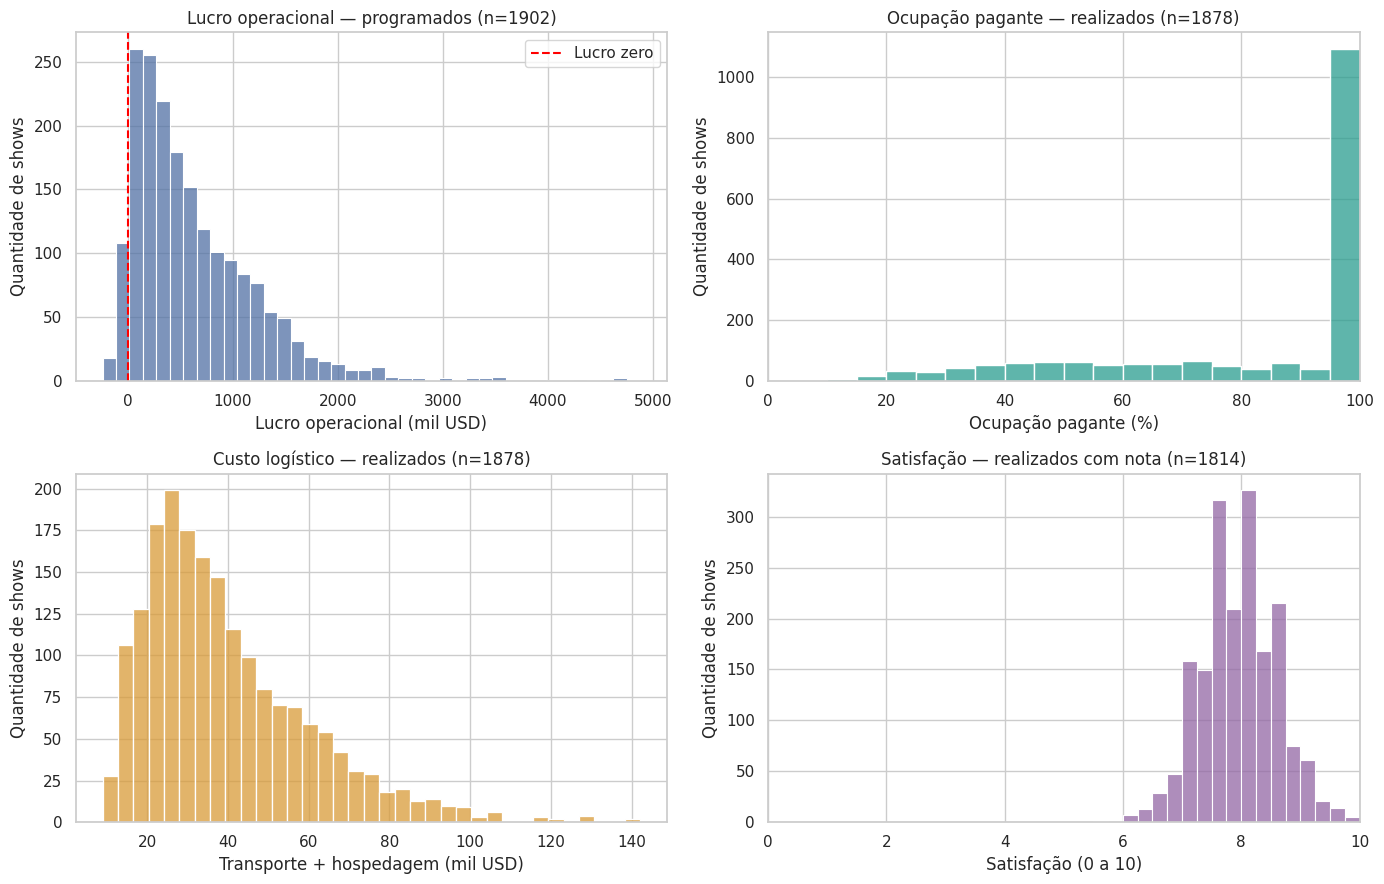

Realizados com ocupação pagante próxima de 99%: 1058 de 1878 (56.34%).

Prejuízo por status:


,total_shows,shows_com_prejuizo,percentual_com_prejuizo
status_show,,,
cancelado,24,24,100.00
realizado,1878,76,4.05


In [9]:
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Lucro: toda a programação
sns.histplot(
    x=df["lucro_operacional_usd"] / 1_000,
    bins=40,
    ax=axes[0, 0],
    color="#5271A5"
)
axes[0, 0].axvline(0, color="red", linestyle="--", label="Lucro zero")
axes[0, 0].set(
    title=f"Lucro operacional — programados (n={len(df)})",
    xlabel="Lucro operacional (mil USD)",
    ylabel="Quantidade de shows"
)
axes[0, 0].legend()

# Ocupação: realizados
sns.histplot(
    data=df_realizados,
    x="ocupacao_pagante_pct",
    bins=np.linspace(0, 100, 21),
    ax=axes[0, 1],
    color="#299D8F"
)
axes[0, 1].set(
    title=f"Ocupação pagante — realizados (n={len(df_realizados)})",
    xlabel="Ocupação pagante (%)",
    ylabel="Quantidade de shows",
    xlim=(0, 100)
)

# Logística: realizados
sns.histplot(
    x=df_realizados["custo_logistico_usd"] / 1_000,
    bins=35,
    ax=axes[1, 0],
    color="#D99B38"
)
axes[1, 0].set(
    title=f"Custo logístico — realizados (n={len(df_realizados)})",
    xlabel="Transporte + hospedagem (mil USD)",
    ylabel="Quantidade de shows"
)

# Satisfação: somente notas disponíveis
notas = df_realizados["satisfacao_publico_0a10"].dropna()

sns.histplot(
    x=notas,
    bins=np.arange(0, 10.25, 0.25),
    ax=axes[1, 1],
    color="#9367A5"
)
axes[1, 1].set(
    title=f"Satisfação — realizados com nota (n={len(notas)})",
    xlabel="Satisfação (0 a 10)",
    ylabel="Quantidade de shows",
    xlim=(0, 10)
)

plt.tight_layout()
plt.show()

# Quantificar a concentração no teto observado
no_teto = np.isclose(
    df_realizados["ocupacao_pagante_pct"],
    99,
    rtol=0,
    atol=0.01
)

print(
    f"Realizados com ocupação pagante próxima de 99%: "
    f"{no_teto.sum()} de {len(df_realizados)} "
    f"({no_teto.mean():.2%})."
)

# Separar prejuízos de cancelados e realizados
print("\nPrejuízo por status:")
display(
    df.groupby("status_show")
    .agg(
        total_shows=("id_show", "size"),
        shows_com_prejuizo=("show_com_prejuizo", "sum"),
        percentual_com_prejuizo=("show_com_prejuizo", "mean")
    )
    .assign(
        percentual_com_prejuizo=lambda t:
            t["percentual_com_prejuizo"] * 100
    )
    .round(2)
)

## 5. Investigação das hipóteses e desenvolvimento dos insights

Após a compreensão, preparação e exploração inicial dos dados,
esta seção investiga três ideias:

1. Shows com produção premium apresentam maior lucro operacional?
2. Shows com produção premium apresentam maior satisfação do público?
3. Shows consecutivos no mesmo país apresentam menor custo de transporte?

Para cada pergunta, apresentaremos as hipóteses, o código utilizado,
tabelas e gráficos, seguidos da interpretação dos resultados.

As conclusões poderão apoiar ou contrariar as ideias iniciais.
Cada investigação incluirá uma ação proposta e uma forma de avaliar
seu resultado.

Os dados são simulados e as associações observadas não demonstram,
isoladamente, relações de causa e efeito.

### 5.1. Produção premium apresenta maior lucro por show?

**Ideia inicial:** uma produção mais elaborada pode acompanhar receitas
maiores, mas também exige custos adicionais. Vamos investigar qual
resultado aparece no lucro operacional.

Primeiro, compararemos os padrões essencial, padrão e premium.
Depois, repetiremos a comparação por tipo de local, para verificar
se o resultado geral mistura shows de portes diferentes.

A análise financeira inclui cancelamentos e utiliza o lucro por show.
As comparações são exploratórias e não demonstram causalidade.

Resultado geral por padrão de produção:


,shows,turnes,lucro_medio_usd,lucro_mediano_usd,percentual_prejuizo
padrao_producao,,,,,
essencial,428,42,679614.66,548719.73,2.57
padrao,1049,99,629371.22,468821.04,4.86
premium,425,39,574692.66,376577.43,8.94



Lucro médio (USD), comparando locais do mesmo tipo:


padrao_producao,essencial,padrao,premium
tipo_local,,,
teatro,122315.01,136014.22,91150.29
arena,743743.03,707879.65,636934.21
estadio,1336512.25,1085749.66,963684.67



Quantidade de shows em cada comparação:


padrao_producao,essencial,padrao,premium
tipo_local,,,
teatro,89,220,79
arena,292,714,295
estadio,47,115,51


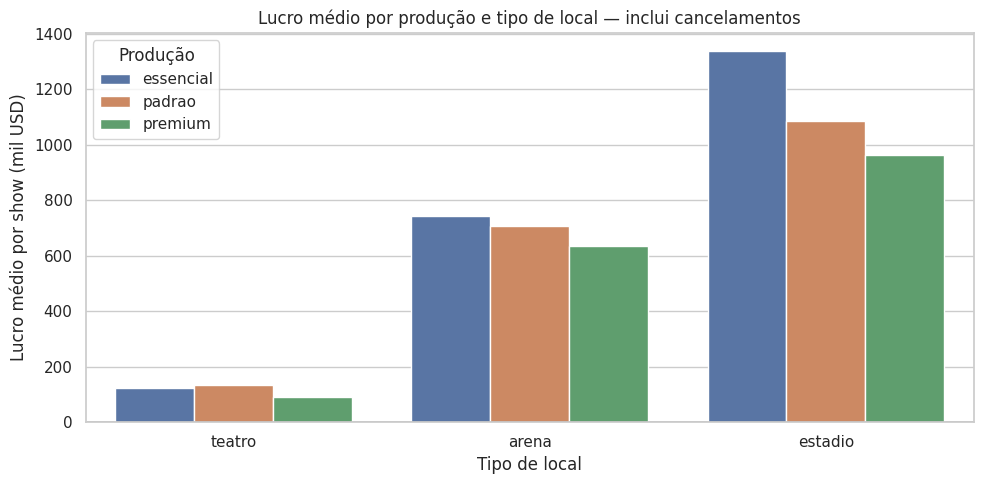

In [10]:
ordem_producao = ["essencial", "padrao", "premium"]
ordem_local = ["teatro", "arena", "estadio"]

# 1. Comparação geral: inclui cancelamentos
resumo_producao = (
    df.groupby("padrao_producao")
    .agg(
        shows=("id_show", "size"),
        turnes=("id_turne", "nunique"),
        lucro_medio_usd=("lucro_operacional_usd", "mean"),
        lucro_mediano_usd=("lucro_operacional_usd", "median"),
        percentual_prejuizo=("show_com_prejuizo", "mean")
    )
    .reindex(ordem_producao)
)

resumo_producao["percentual_prejuizo"] *= 100

print("Resultado geral por padrão de produção:")
display(resumo_producao.round(2))

# 2. Comparação dentro de cada tipo de local
resumo_por_local = (
    df.groupby(["tipo_local", "padrao_producao"])
    .agg(
        shows=("id_show", "size"),
        lucro_medio_usd=("lucro_operacional_usd", "mean")
    )
    .reset_index()
)

print("\nLucro médio (USD), comparando locais do mesmo tipo:")
display(
    resumo_por_local.pivot(
        index="tipo_local",
        columns="padrao_producao",
        values="lucro_medio_usd"
    )
    .reindex(index=ordem_local, columns=ordem_producao)
    .round(2)
)

print("\nQuantidade de shows em cada comparação:")
display(
    resumo_por_local.pivot(
        index="tipo_local",
        columns="padrao_producao",
        values="shows"
    )
    .reindex(index=ordem_local, columns=ordem_producao)
)

# 3. Gráfico das médias por tipo de local
dados_grafico = resumo_por_local.assign(
    lucro_medio_mil_usd=resumo_por_local["lucro_medio_usd"] / 1_000
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=dados_grafico,
    x="tipo_local",
    y="lucro_medio_mil_usd",
    hue="padrao_producao",
    order=ordem_local,
    hue_order=ordem_producao,
    errorbar=None
)

plt.axhline(0, color="black", linewidth=1)
plt.title("Lucro médio por produção e tipo de local — inclui cancelamentos")
plt.xlabel("Tipo de local")
plt.ylabel("Lucro médio por show (mil USD)")
plt.legend(title="Produção")
plt.tight_layout()
plt.show()

#### Comparação estatística exploratória: premium versus essencial

A comparação utilizará o lucro médio por show de cada turnê.
Cada turnê terá o mesmo peso, independentemente da quantidade de datas.

- H₀: a média desse indicador é igual nas turnês premium e essenciais.
- H₁: a média desse indicador é diferente entre os dois padrões.

Será utilizado o teste t de Welch, que permite variâncias diferentes
entre os grupos. O nível de significância adotado será de 5%.

A análise é exploratória, pois a comparação foi escolhida após observar
os dados. A agregação reduz a dependência entre shows da mesma turnê,
mas turnês do mesmo grupo ainda podem compartilhar características.
O teste não demonstra causalidade.

In [11]:
from scipy.stats import ttest_ind

# Confirmar que cada turnê possui um único padrão de produção
producao_por_turne = df.groupby("id_turne")["padrao_producao"].nunique()

assert producao_por_turne.eq(1).all(), (
    "Há turnês com mais de um padrão de produção. "
    "Precisamos rever a comparação antes do teste."
)

# Inclui todos os shows programados, inclusive cancelamentos
turnes = (
    df.groupby("id_turne")
    .agg(
        producao=("padrao_producao", "first"),
        lucro_medio_por_show=("lucro_operacional_usd", "mean")
    )
)

premium = turnes.loc[
    turnes["producao"].eq("premium"), "lucro_medio_por_show"
]

essencial = turnes.loc[
    turnes["producao"].eq("essencial"), "lucro_medio_por_show"
]

teste = ttest_ind(premium, essencial, equal_var=False)

display(pd.DataFrame({
    "producao": ["premium", "essencial"],
    "quantidade_turnes": [len(premium), len(essencial)],
    "media_das_medias_por_turne_usd": [
        premium.mean(), essencial.mean()
    ],
    "desvio_padrao_usd": [
        premium.std(), essencial.std()
    ]
}).round(2))

print(
    "Diferença premium − essencial: "
    f"US$ {premium.mean() - essencial.mean():,.2f}"
)
print(f"Estatística t: {teste.statistic:.3f}")
print(f"Valor-p: {teste.pvalue:.6g}")

,producao,quantidade_turnes,media_das_medias_por_turne_usd,desvio_padrao_usd
0,premium,39,568817.34,455468.62
1,essencial,42,678281.57,480760.21


Diferença premium − essencial: US$ -109,464.23
Estatística t: -1.052
Valor-p: 0.295903


#### Insight 1 — Produção premium não acompanha maior lucro observado

Na comparação por show, a produção premium apresentou lucro médio
de US$ 574.692,66, contra US$ 679.614,66 na essencial.
A mediana também foi menor, e a proporção de shows com prejuízo
foi de 8,94% no premium e 2,57% no essencial.

A produção premium apresentou menor lucro médio nos três tipos
de local: teatro, arena e estádio.

Ao atribuir o mesmo peso a cada turnê, a diferença premium menos
essencial foi de −US$ 109.464,23. Entretanto, o teste t de Welch,
comparando 39 turnês premium e 42 essenciais, apresentou
p = 0,295903. Ao nível de 5%, não rejeitamos a hipótese de
igualdade das médias.

**Conclusão:** a ideia de maior lucro no premium não foi apoiada
pelas comparações observadas. Contudo, o teste não forneceu
evidência suficiente para afirmar uma diferença entre as médias.
Não rejeitar H₀ não significa demonstrar que os padrões são iguais.

**Limitações:** a comparação é exploratória e não isola diferenças
de grupo, mercado ou calendário. Turnês do mesmo grupo podem ser
dependentes, aspecto não incorporado pelo teste de Welch.
Os resultados não demonstram que a produção premium cause menor lucro.

**Ação proposta:** exigir uma projeção de receitas e custos adicionais
antes de aprovar o investimento em produção premium, sem presumir
que uma estrutura mais elaborada garantirá maior retorno.

**Como avaliar:** acompanhar lucro por show, margem e frequência
de prejuízo em operações comparáveis, verificando se o retorno
adicional previsto se concretiza.

AAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAA

### 5.2. Produção premium apresenta maior satisfação do público?

**Ideia inicial:** uma estrutura de produção mais elaborada pode
estar associada a melhores avaliações do público.

Serão utilizados apenas shows realizados com satisfação registrada.
Compararemos os três padrões de produção, observando quantidade
de avaliações, média, mediana e distribuição das notas.

Para a comparação estatística entre premium e essencial,
utilizaremos a satisfação média de cada turnê:

- H₀: a média desse indicador é igual nos dois padrões.
- H₁: a média desse indicador é diferente entre os padrões.

O teste será bilateral, com nível de significância de 5%.
A investigação é exploratória e não demonstra causalidade.

Satisfação por padrão de produção:


,shows_com_nota,turnes,satisfacao_media,satisfacao_mediana,desvio_padrao,cobertura_notas_pct
padrao_producao,,,,,,
essencial,405,42,7.78,7.8,0.59,95.52
padrao,1001,99,7.92,7.9,0.64,96.81
premium,408,39,8.13,8.1,0.63,97.14


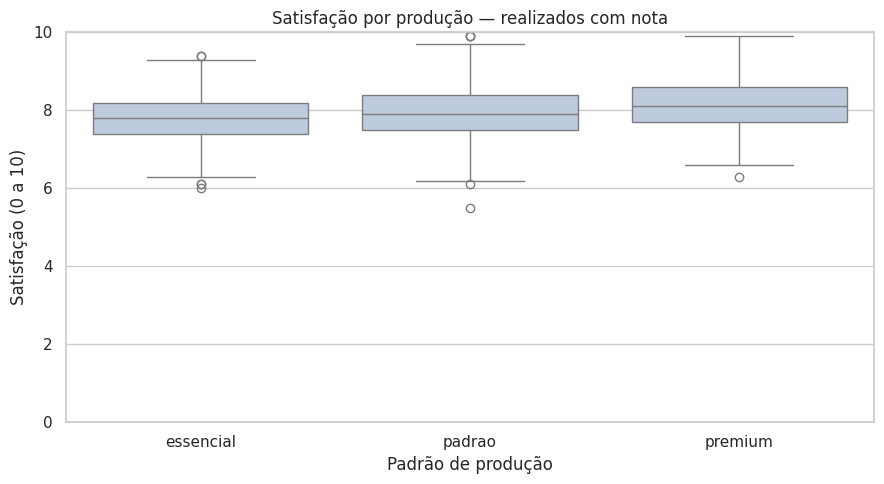

Satisfação média por tipo de local:


padrao_producao,essencial,padrao,premium
tipo_local,,,
teatro,7.78,7.90,8.16
arena,7.77,7.91,8.10
estadio,7.87,7.98,8.24



Comparação das médias por turnê:


,producao,quantidade_turnes,media_das_medias_por_turne,desvio_padrao
0,premium,39,8.135,0.279
1,essencial,42,7.798,0.267


Diferença premium − essencial: 0.337 ponto(s)
Estatística t: 5.541
Valor-p: 3.93577e-07


In [12]:
# Apenas realizados com nota disponível
base_satisfacao = df_realizados.dropna(
    subset=["satisfacao_publico_0a10"]
).copy()

# 1. Comparação descritiva
resumo_satisfacao_producao = (
    base_satisfacao.groupby("padrao_producao")
    .agg(
        shows_com_nota=("id_show", "size"),
        turnes=("id_turne", "nunique"),
        satisfacao_media=("satisfacao_publico_0a10", "mean"),
        satisfacao_mediana=("satisfacao_publico_0a10", "median"),
        desvio_padrao=("satisfacao_publico_0a10", "std")
    )
    .reindex(ordem_producao)
)

# Mostrar também a cobertura das avaliações
total_realizados = (
    df_realizados.groupby("padrao_producao").size()
)

resumo_satisfacao_producao["cobertura_notas_pct"] = (
    resumo_satisfacao_producao["shows_com_nota"]
    / total_realizados * 100
)

print("Satisfação por padrão de produção:")
display(resumo_satisfacao_producao.round(2))

# 2. Distribuição das notas
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=base_satisfacao,
    x="padrao_producao",
    y="satisfacao_publico_0a10",
    order=ordem_producao,
    color="#B9C9E3"
)

plt.title("Satisfação por produção — realizados com nota")
plt.xlabel("Padrão de produção")
plt.ylabel("Satisfação (0 a 10)")
plt.ylim(0, 10)
plt.tight_layout()
plt.show()

# 3. Conferir se o padrão descritivo aparece em locais do mesmo tipo
print("Satisfação média por tipo de local:")
display(
    base_satisfacao.pivot_table(
        index="tipo_local",
        columns="padrao_producao",
        values="satisfacao_publico_0a10",
        aggfunc="mean"
    )
    .reindex(index=ordem_local, columns=ordem_producao)
    .round(2)
)

# 4. Comparação estatística por turnê
# A constância do padrão de produção por turnê foi verificada no insight 1
satisfacao_turnes = (
    base_satisfacao.groupby("id_turne")
    .agg(
        producao=("padrao_producao", "first"),
        satisfacao_media=("satisfacao_publico_0a10", "mean"),
        shows_com_nota=("id_show", "size")
    )
)

notas_premium = satisfacao_turnes.loc[
    satisfacao_turnes["producao"].eq("premium"),
    "satisfacao_media"
]

notas_essencial = satisfacao_turnes.loc[
    satisfacao_turnes["producao"].eq("essencial"),
    "satisfacao_media"
]

teste_satisfacao = ttest_ind(
    notas_premium,
    notas_essencial,
    equal_var=False
)

print("\nComparação das médias por turnê:")
display(pd.DataFrame({
    "producao": ["premium", "essencial"],
    "quantidade_turnes": [len(notas_premium), len(notas_essencial)],
    "media_das_medias_por_turne": [
        notas_premium.mean(), notas_essencial.mean()
    ],
    "desvio_padrao": [
        notas_premium.std(), notas_essencial.std()
    ]
}).round(3))

print(
    "Diferença premium − essencial: "
    f"{notas_premium.mean() - notas_essencial.mean():.3f} ponto(s)"
)
print(f"Estatística t: {teste_satisfacao.statistic:.3f}")
print(f"Valor-p: {teste_satisfacao.pvalue:.6g}")

#### Insight 2 — Produção premium acompanha maior satisfação do público

Foram analisados 1.814 shows realizados com avaliação registrada:
405 essenciais, 1.001 padrão e 408 premium.

A satisfação média foi de 7,78 na produção essencial, 7,92 na padrão
e 8,13 na premium. As medianas seguiram a mesma ordem.
A produção premium também apresentou maior satisfação média
nos três tipos de local: teatro, arena e estádio.

Na comparação entre 39 turnês premium e 42 essenciais,
a diferença entre as médias por turnê foi de 0,337 ponto.
O teste t de Welch apresentou p ≈ 3,94 × 10⁻⁷.
Ao nível de 5%, rejeitamos H₀ no teste exploratório aplicado.

**Conclusão:** os resultados apoiam a ideia de que a produção premium
está associada a maior satisfação neste cenário simulado.
A diferença observada é de aproximadamente um terço de ponto
na escala de 0 a 10.

**Limitações:** a comparação não demonstra causalidade.
Características dos grupos, mercados e públicos podem contribuir
para a diferença. Turnês do mesmo grupo podem ser dependentes,
aspecto não incorporado pelo teste. Também existem avaliações ausentes,
e coberturas semelhantes não garantem ausência de viés.

**Ação proposta:** avaliar o investimento premium considerando
simultaneamente a experiência do público e o resultado financeiro,
definindo previamente qual melhoria de satisfação justificaria
o custo adicional.

**Como avaliar:** em um piloto com shows comparáveis, acompanhar
satisfação, cobertura das avaliações, custo de produção e margem.
Sempre que viável, distribuir as alternativas de produção por sorteio
para avaliar melhor o efeito da mudança.

AAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAA

### 5.3. Popularidade digital é o mesmo que ocupação dos shows?

**Ideia investigada:** shows com menos seguidores locais, mas maior
engajamento, podem apresentar maior ocupação que shows com muitos
seguidores e menor engajamento.

Serão analisados shows realizados com seguidores e engajamento
registrados. Cada variável será dividida pela mediana da amostra,
formando quatro perfis.

Compararemos quantidade de shows, ocupação média e mediana,
além da capacidade mediana dos locais. A comparação também será
apresentada separadamente por tipo de local.

Os cortes são exploratórios. A ocupação depende da capacidade
escolhida e possui concentração no teto de 99%, portanto não
representa toda a demanda potencial por ingressos.

Shows realizados: 1878
Shows utilizados: 1811
Excluídos por ausência: 67

Corte de seguidores: 8.440 milhões
Corte de engajamento: 4.870%
Valores iguais à mediana entram na categoria alta.

Resultado por perfil digital:


,shows,grupos,turnes,ocupacao_media_pct,ocupacao_mediana_pct,capacidade_mediana
perfil_digital,,,,,,
Menos seguidores / menor engajamento,424,16,100,70.98,74.94,12000.0
Menos seguidores / maior engajamento,481,17,99,77.81,99.00,12000.0
Mais seguidores / menor engajamento,475,15,96,85.50,99.00,16000.0
Mais seguidores / maior engajamento,431,17,101,90.94,99.00,16000.0



Ocupação média (%) por tipo de local:


perfil_digital,Menos seguidores / menor engajamento,Menos seguidores / maior engajamento,Mais seguidores / menor engajamento,Mais seguidores / maior engajamento
tipo_local,,,,
teatro,96.52,98.71,99.00,99.00
arena,63.83,76.66,89.49,94.83
estadio,24.90,34.65,53.75,62.63



Quantidade de shows em cada comparação:


perfil_digital,Menos seguidores / menor engajamento,Menos seguidores / maior engajamento,Mais seguidores / menor engajamento,Mais seguidores / maior engajamento
tipo_local,,,,
teatro,126,128,45,45
arena,270,299,365,328
estadio,28,54,65,58


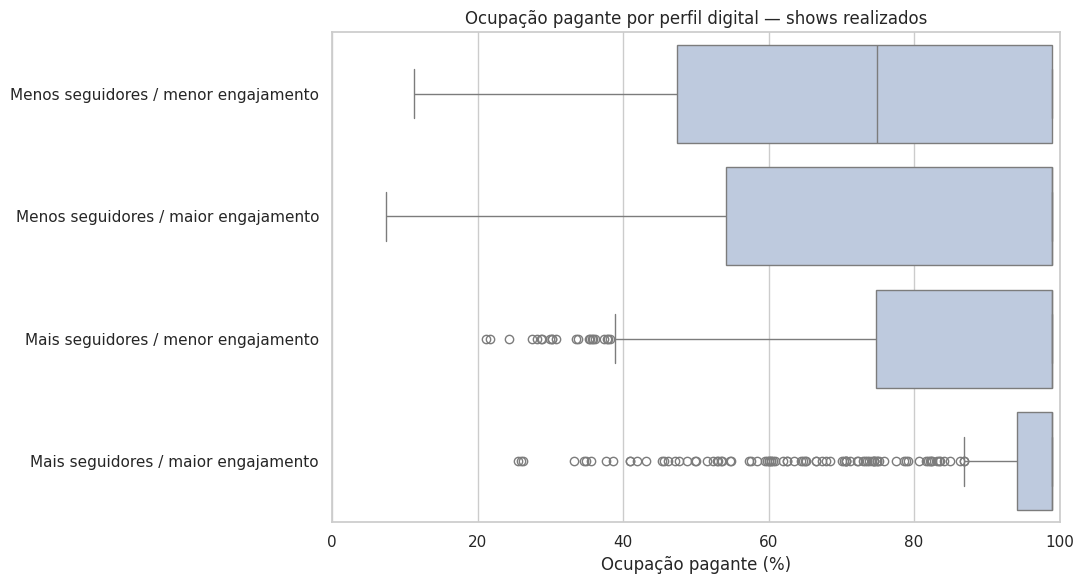


Diferença de ocupação média:
(menos seguidores / maior engajamento) − (mais seguidores / menor engajamento)
-7.69 pontos percentuais


In [13]:
# 1. Selecionar apenas as medidas necessárias
base_demanda = df_realizados.dropna(subset=[
    "seguidores_locais_milhoes",
    "engajamento_redes_pct"
]).copy()

print(f"Shows realizados: {len(df_realizados)}")
print(f"Shows utilizados: {len(base_demanda)}")
print(f"Excluídos por ausência: {len(df_realizados) - len(base_demanda)}")

# 2. Definir os cortes na amostra utilizada
corte_seguidores = base_demanda["seguidores_locais_milhoes"].median()
corte_engajamento = base_demanda["engajamento_redes_pct"].median()

print(f"\nCorte de seguidores: {corte_seguidores:.3f} milhões")
print(f"Corte de engajamento: {corte_engajamento:.3f}%")
print("Valores iguais à mediana entram na categoria alta.")

seguidores_altos = (
    base_demanda["seguidores_locais_milhoes"] >= corte_seguidores
)
engajamento_alto = (
    base_demanda["engajamento_redes_pct"] >= corte_engajamento
)

ordem_perfis = [
    "Menos seguidores / menor engajamento",
    "Menos seguidores / maior engajamento",
    "Mais seguidores / menor engajamento",
    "Mais seguidores / maior engajamento"
]

base_demanda["perfil_digital"] = np.select(
    [
        ~seguidores_altos & ~engajamento_alto,
        ~seguidores_altos & engajamento_alto,
        seguidores_altos & ~engajamento_alto,
        seguidores_altos & engajamento_alto
    ],
    ordem_perfis,
    default="Não classificado"
)

# 3. Comparação geral
resumo_perfis = (
    base_demanda.groupby("perfil_digital")
    .agg(
        shows=("id_show", "size"),
        grupos=("grupo", "nunique"),
        turnes=("id_turne", "nunique"),
        ocupacao_media_pct=("ocupacao_pagante_pct", "mean"),
        ocupacao_mediana_pct=("ocupacao_pagante_pct", "median"),
        capacidade_mediana=("capacidade", "median")
    )
    .reindex(ordem_perfis)
)

print("\nResultado por perfil digital:")
display(resumo_perfis.round(2))

# 4. Comparação por tipo de local, mantendo os mesmos cortes
print("\nOcupação média (%) por tipo de local:")
display(
    base_demanda.pivot_table(
        index="tipo_local",
        columns="perfil_digital",
        values="ocupacao_pagante_pct",
        aggfunc="mean"
    )
    .reindex(index=ordem_local, columns=ordem_perfis)
    .round(2)
)

print("\nQuantidade de shows em cada comparação:")
display(
    base_demanda.pivot_table(
        index="tipo_local",
        columns="perfil_digital",
        values="id_show",
        aggfunc="count"
    )
    .reindex(index=ordem_local, columns=ordem_perfis)
)

# 5. Gráfico: distribuição, incluindo o teto de ocupação
plt.figure(figsize=(11, 6))

sns.boxplot(
    data=base_demanda,
    x="ocupacao_pagante_pct",
    y="perfil_digital",
    order=ordem_perfis,
    color="#B9C9E3"
)

plt.title("Ocupação pagante por perfil digital — shows realizados")
plt.xlabel("Ocupação pagante (%)")
plt.ylabel("")
plt.xlim(0, 100)
plt.tight_layout()
plt.show()

# 6. Contraste central da investigação
perfil_engajado = ordem_perfis[1]
perfil_seguidores = ordem_perfis[2]

diferenca = (
    resumo_perfis.loc[perfil_engajado, "ocupacao_media_pct"]
    - resumo_perfis.loc[perfil_seguidores, "ocupacao_media_pct"]
)

print(
    "\nDiferença de ocupação média:\n"
    "(menos seguidores / maior engajamento) − "
    "(mais seguidores / menor engajamento)\n"
    f"{diferenca:.2f} pontos percentuais"
)

#### Comparação dos perfis dentro dos mesmos grupos musicais

Compararemos dois perfis:
- Menos seguidores e maior engajamento.
- Mais seguidores e menor engajamento.

Para cada grupo musical que tenha shows nos dois perfis, calcularemos
a ocupação média de cada perfil. Cada grupo fornecerá um par de valores.

Aplicaremos o teste não paramétrico de Wilcoxon pareado, bilateral,
com nível de significância de 5%.

H₀: a distribuição das diferenças pareadas está centrada em zero.
H₁: essa distribuição não está centrada em zero.

A interpretação como teste de localização pressupõe simetria
das diferenças. A análise é exploratória e não controla todas
as diferenças de local, mercado ou calendário.

In [14]:
from scipy.stats import wilcoxon

perfil_a = "Menos seguidores / maior engajamento"
perfil_b = "Mais seguidores / menor engajamento"

# Uma média por grupo musical e perfil digital
pares_grupos = (
    base_demanda.loc[
        base_demanda["perfil_digital"].isin([perfil_a, perfil_b])
    ]
    .groupby(["grupo", "perfil_digital"])["ocupacao_pagante_pct"]
    .mean()
    .unstack("perfil_digital")
    .reindex(columns=[perfil_a, perfil_b])
)

# Manter apenas grupos presentes nos dois perfis
pares_completos = pares_grupos.dropna().copy()

pares_completos["diferenca_pp"] = (
    pares_completos[perfil_a] - pares_completos[perfil_b]
)

print(f"Grupos com os dois perfis: {len(pares_completos)}")
display(pares_completos.round(2))

diferencas = pares_completos["diferenca_pp"]

print(
    "\nDiferença média entre os pares: "
    f"{diferencas.mean():.2f} pontos percentuais"
)
print(
    "Diferença mediana entre os pares: "
    f"{diferencas.median():.2f} pontos percentuais"
)

if len(diferencas) < 2 or np.isclose(diferencas, 0).all():
    print("Dados insuficientes ou diferenças todas nulas para este teste.")
else:
    teste_demanda = wilcoxon(
        pares_completos[perfil_a],
        pares_completos[perfil_b],
        alternative="two-sided",
        method="auto"
    )

    print(f"Estatística de Wilcoxon: {teste_demanda.statistic:.3f}")
    print(f"Valor-p: {teste_demanda.pvalue:.6g}")

Grupos com os dois perfis: 12


perfil_digital,Menos seguidores / maior engajamento,Mais seguidores / menor engajamento,diferenca_pp
grupo,,,
(G)I-DLE,81.87,78.68,3.19
ATEEZ,63.96,91.64,-27.68
Dreamcatcher,99.00,95.00,4.00
ITZY,69.65,84.18,-14.53
IVE,83.86,80.76,3.10
LE SSERAFIM,76.28,78.52,-2.25
STAYC,79.28,99.00,-19.72
THE BOYZ,57.63,69.24,-11.61
TOMORROW X TOGETHER,89.89,99.00,-9.11



Diferença média entre os pares: -9.36 pontos percentuais
Diferença mediana entre os pares: -10.36 pontos percentuais
Estatística de Wilcoxon: 14.000
Valor-p: 0.0522461


#### Insight 3 — Maior engajamento não compensou menos seguidores no contraste observado

Foram utilizados 1.811 shows realizados com seguidores e engajamento
registrados; 67 foram excluídos por ausência de seguidores.

Os perfis foram definidos pelas medianas da amostra:
8,44 milhões de seguidores e 4,87% de engajamento.

O perfil com menos seguidores e maior engajamento apresentou
ocupação média de 77,81%, contra 85,50% no perfil com mais seguidores
e menor engajamento: diferença de −7,69 pontos percentuais.

Ao comparar os mesmos grupos musicais, 12 tinham shows nos dois perfis.
Em oito, a ocupação foi maior no perfil com mais seguidores e menor
engajamento; em quatro, ocorreu o contrário.
A diferença média entre os pares foi de −9,36 pontos percentuais.

O teste de Wilcoxon apresentou p = 0,0522461.
Ao nível de 5%, não rejeitamos H₀. Isso não demonstra igualdade
entre os perfis, mas indica evidência insuficiente no teste aplicado.

**Conclusão:** a ideia de que maior engajamento compensaria menos
seguidores não foi apoiada pelas comparações descritivas.
Entretanto, não encontramos diferença estatisticamente significativa
no teste pareado ao nível de 5%.

Um resultado complementar foi a concentração da ocupação próxima
da lotação nos teatros, enquanto arenas e estádios apresentaram
diferenças maiores entre os perfis digitais.

**Limitações:** os cortes pelas medianas são exploratórios.
O pareamento por grupo não iguala países, preços, capacidades
ou calendários. O teste utiliza apenas 12 grupos e pressupõe
simetria das diferenças para sua interpretação de localização.
A ocupação possui efeito de teto e não mede toda a demanda potencial.
Os resultados não demonstram que seguidores causem maior ocupação.

**Ação proposta:** combinar seguidores locais, engajamento e ritmo
de pré-vendas na escolha da capacidade, evitando selecionar
um local grande apenas por uma taxa elevada de engajamento.

**Como avaliar:** acompanhar ocupação pagante, margem e velocidade
de vendas em novos shows. Comparar as previsões com os resultados
e verificar se a escolha de capacidade reduz lugares ociosos
sem limitar excessivamente as vendas.

A associação pode não se manter após uma mudança de capacidade:
um local menor pode elevar a ocupação percentual e, ainda assim,
reduzir o público total e o lucro.

QUEM É O AMULETO DO LUCRO E DA SATISFAÇÃO DAS KPOPERS

In [15]:
print("Quantidade de integrantes de referência por grupo:")
display(
    df.groupby("grupo")["integrante_referencia"]
    .nunique()
    .sort_values(ascending=False)
    .to_frame("quantidade_integrantes_referencia")
)

Quantidade de integrantes de referência por grupo:


,quantidade_integrantes_referencia
grupo,
(G)I-DLE,1
ATEEZ,1
Dreamcatcher,1
ENHYPEN,1
ITZY,1
IVE,1
KARD,1
LE SSERAFIM,1
MONSTA X,1


## 6. Bônus — Ranking dos amuletos

Quais integrantes de referência estão associados aos grupos com
maior lucro médio por show e maior satisfação média?

Cada grupo possui apenas um integrante de referência.
Portanto, este ranking descreve os resultados dos grupos:
não mede desempenho individual, não confirma presença nos shows
e não demonstra influência do integrante.

Os eventos e valores são simulados. O bônus não substitui
os três insights principais.

 Amuletos do caixa — maior lucro médio por show:


,integrante_referencia,grupo,shows_programados,lucro_medio_usd
16,Soobin,TOMORROW X TOGETHER,94,1314951.91
12,S.Coups,SEVENTEEN,102,1173730.64
14,Bang Chan,Stray Kids,93,1078503.26
1,Hongjoong,ATEEZ,92,1033548.95
0,Soyeon,(G)I-DLE,104,899043.22



 Amuletos do público — maior satisfação média:


,integrante_referencia,grupo,shows_com_nota,satisfacao_media
8,Shownu,MONSTA X,98,8.27
17,Choi Hyun-suk,TREASURE,90,8.26
9,Lily,NMIXX,87,8.15
16,Soobin,TOMORROW X TOGETHER,92,8.13
7,Kim Chaewon,LE SSERAFIM,83,8.07


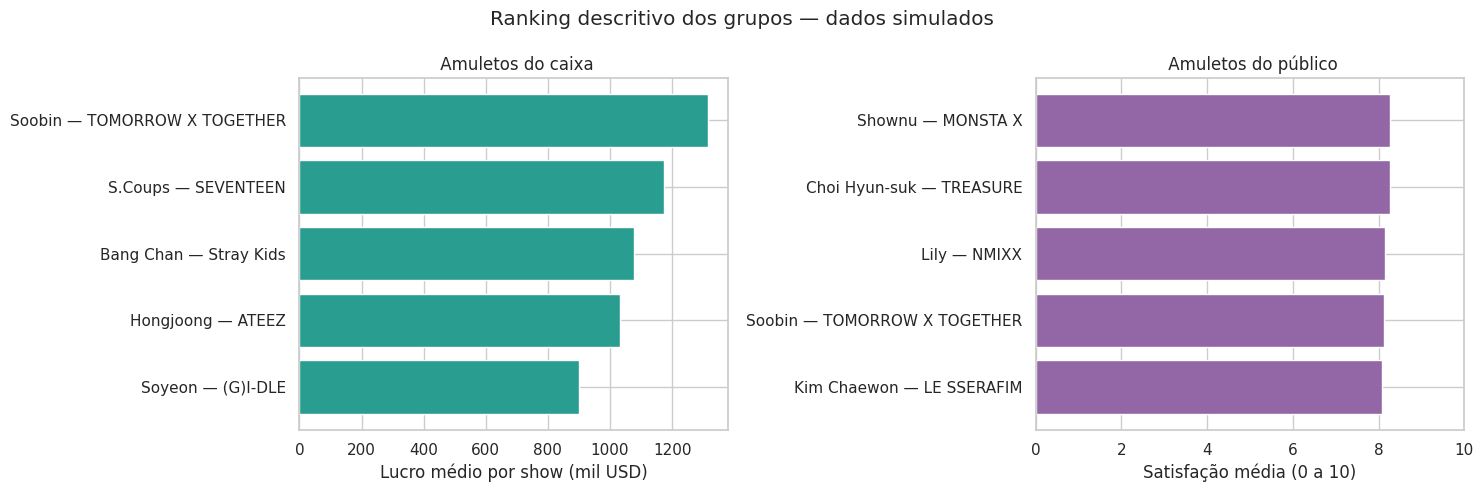

In [18]:
# Lucro: inclui cancelamentos
ranking_amuletos = (
    df.groupby(["grupo", "integrante_referencia"])
    .agg(
        shows_programados=("id_show", "size"),
        lucro_medio_usd=("lucro_operacional_usd", "mean")
    )
)

# Satisfação: apenas realizados com nota
satisfacao_amuletos = (
    df_realizados.groupby(["grupo", "integrante_referencia"])
    .agg(
        shows_com_nota=("satisfacao_publico_0a10", "count"),
        satisfacao_media=("satisfacao_publico_0a10", "mean")
    )
)

ranking_amuletos = (
    ranking_amuletos.join(satisfacao_amuletos)
    .reset_index()
)

ranking_amuletos["rotulo"] = (
    ranking_amuletos["integrante_referencia"]
    + " — " + ranking_amuletos["grupo"]
)

top_lucro = ranking_amuletos.nlargest(5, "lucro_medio_usd")
top_satisfacao = ranking_amuletos.nlargest(5, "satisfacao_media")

print(" Amuletos do caixa — maior lucro médio por show:")
display(top_lucro[[
    "integrante_referencia", "grupo",
    "shows_programados", "lucro_medio_usd"
]].round(2))

print("\n Amuletos do público — maior satisfação média:")
display(top_satisfacao[[
    "integrante_referencia", "grupo",
    "shows_com_nota", "satisfacao_media"
]].round(2))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].barh(
    top_lucro["rotulo"],
    top_lucro["lucro_medio_usd"] / 1_000,
    color="#299D8F"
)
axes[0].invert_yaxis()
axes[0].set(
    title=" Amuletos do caixa",
    xlabel="Lucro médio por show (mil USD)"
)

axes[1].barh(
    top_satisfacao["rotulo"],
    top_satisfacao["satisfacao_media"],
    color="#9367A5"
)
axes[1].invert_yaxis()
axes[1].set(
    title=" Amuletos do público",
    xlabel="Satisfação média (0 a 10)",
    xlim=(0, 10)
)

fig.suptitle("Ranking descritivo dos grupos — dados simulados")
plt.tight_layout()
plt.show()

### Resultado do bônus

Soobin, representante do TOMORROW X TOGETHER, ganhou o título
simbólico de “amuleto do caixa”: seu grupo apresentou o maior
lucro médio por show, aproximadamente US$ 1,315 milhão,
e ficou em quarto lugar em satisfação.

Shownu, representante do MONSTA X, ficou com o título de
“amuleto do público”, com satisfação média de 8,27.

Os títulos são uma brincadeira descritiva: os dados são simulados
e não permitem atribuir esses resultados aos integrantes.